# The excellent dataset: RAW and confirmed files, by mineral

This notebook describes a set of files. It is taken from the two excellent archives,
`excellent_oriented` and `excellent_unoriented`, and holds every export in them whose `FILETYPE`
says RAW and whose identification is confirmed. Nothing else is filtered: no window, no trim, and no
restriction on the excitation wavelength, so the set holds whatever range each file happens to span.

The tables below report how many minerals the set carries, how many files each mineral has, and the
wavenumber range each of those files spans. A mineral whose files do not all span the same range is
marked.


## 1. Setting up

The archives are looked for under `~/Desktop/raman_data` unless `RRUFF_DATA` points somewhere else.
The two archives that make the excellent dataset are named here, and so are the header fields the
set is filtered on.


In [1]:
from __future__ import annotations

import os
import re
import time
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
%matplotlib inline

# The two archives the set is taken from. The rating is RRUFF's own.
ARCHIVES = ["excellent_oriented", "excellent_unoriented"]

# FILETYPE names the export kind, so a RAW file is picked out by that field rather than by the
# file name. STATUS carries RRUFF's sentence about the identification; a sentence recorded as
# "...is not yet confirmed", as the bare "Unconfirmed", or as a wording without the "yet" is
# matched by one of the three markers read as a substring.
UNCONFIRMED_MARKERS = ("not yet confirmed", "not confirmed", "unconfirmed")

# Two ranges are the same range when their ends agree where the exports state them, at the four
# decimals the wavenumber column is written to.
AXIS_DECIMALS = 4

DATA_ROOT = Path(os.environ.get("RRUFF_DATA", Path.home() / "Desktop" / "raman_data")).expanduser()

# Used by the reader below, so they are defined next to the paths rather than inside it.
HEADER_LINE = re.compile(r"^##([^=]+)=(.*)$")
LEADING = "+-."

absent = [name for name in ARCHIVES if not (DATA_ROOT / name).is_dir()]
if absent:
    raise FileNotFoundError(f"these archive directories are missing under {DATA_ROOT}: {absent}")

print(f"reading {len(ARCHIVES)} archives from {DATA_ROOT}")
for name in ARCHIVES:
    print(f"  {name:22s} {len(list((DATA_ROOT / name).glob('*.txt'))):7,d} files")


reading 2 archives from /home/raj/Desktop/raman_data
  excellent_oriented       7,668 files
  excellent_unoriented    11,415 files


## 2. Reading one export

A file is a `##KEY=value` block, then the data rows. The traps the reader has to survive are the
ones the other notebooks describe: a value wrapped onto the following line, a key written twice, and
comment lines inside the data block. The reader is repeated here in full so that this notebook runs
on its own.

`read_spectrum` returns the header fields and a few facts about the data block, and it stops at the
first data row, which is what makes the pass over the archives in section 3 cheap.
`read_block_rows` returns the data rows themselves, `read_pairs` turns those into the two columns of
numbers, and section 4 reads the range from the first of those columns.


In [2]:
def read_spectrum(path):
    """Read one export: its header fields, and facts about its data block.

    Args:
        path (Path): the export to read.

    Returns:
        tuple: the header fields as a dict, and a dict describing the data block with the
        keys points, x_min, x_max, wrapped_values, repeated_keys, comment_notes,
        separator, crlf and encoding.
    """
    raw = path.read_bytes()
    try:
        text = raw.decode("utf-8")
        encoding = "utf-8"
    except UnicodeDecodeError:
        text = raw.decode("utf-8", errors="replace")
        encoding = "utf-8, one byte replaced"
    text = text.replace("\r\n", "\n")
    lines = text.split("\n")

    header, last = {}, None
    wrapped = repeated = notes = 0
    separator = ""
    body = None
    for position, line in enumerate(lines):
        stripped = line.strip()
        if not stripped:
            continue
        if stripped[0] == "#":
            match = HEADER_LINE.match(stripped)
            if match is None:
                notes += 1
                continue
            key, value = match.group(1).strip(), match.group(2).strip()
            if key == "END":
                body = position + 1
                break
            if key in header:
                repeated += 1
            header[key] = value
            last = key
            continue
        head = stripped[0]
        if head.isdigit() or head in LEADING:
            fields = stripped.replace(",", " ").split()
            if len(fields) == 2:
                try:
                    float(fields[0])
                    float(fields[1])
                except ValueError:
                    pass
                else:
                    body = position
                    separator = ("tab" if "\t" in line
                                 else "comma" if "," in line else "space")
                    break
        if last is not None:
            header[last] = header[last] + " " + stripped
            wrapped += 1

    points, first_row, last_row = 0, None, None
    for line in lines[body:] if body is not None else ():
        stripped = line.strip()
        if not stripped:
            continue
        if stripped.startswith("##END"):
            break
        if stripped[0] == "#":
            continue
        head = stripped[0]
        if head.isdigit() or head in LEADING:
            points += 1
            if first_row is None:
                first_row = stripped
            last_row = stripped

    x_min = float(first_row.replace(",", " ").split()[0]) if first_row else None
    x_max = float(last_row.replace(",", " ").split()[0]) if last_row else None
    if x_min is not None and x_max is not None and x_min > x_max:
        x_min, x_max = x_max, x_min

    layout = {
        "points": points, "x_min": x_min, "x_max": x_max,
        "wrapped_values": wrapped, "repeated_keys": repeated, "comment_notes": notes,
        "separator": separator, "crlf": b"\r\n" in raw,
        "encoding": encoding,
    }
    return header, layout


def read_block_rows(path):
    """The data rows of one export, with the header and any comment lines removed.

    Args:
        path (Path): the export to read.

    Returns:
        list: the stripped lines of the data block, in file order.
    """
    text = path.read_text(encoding="utf-8", errors="replace").replace("\r\n", "\n")
    lines = text.split("\n")

    body = None
    for position, line in enumerate(lines):
        stripped = line.strip()
        if not stripped:
            continue
        if stripped[0] == "#":
            match = HEADER_LINE.match(stripped)
            if match is not None and match.group(1).strip() == "END":
                body = position + 1
                break
            continue
        head = stripped[0]
        if head.isdigit() or head in LEADING:
            fields = stripped.replace(",", " ").split()
            if len(fields) == 2:
                try:
                    float(fields[0])
                    float(fields[1])
                except ValueError:
                    pass
                else:
                    body = position
                    break

    rows = []
    for line in lines[body:] if body is not None else ():
        stripped = line.strip()
        if not stripped or stripped.startswith("#"):
            continue
        rows.append(stripped)
    return rows


def read_pairs(path):
    """The two columns of one export's data block, in the order the file writes them.

    Args:
        path (Path): the export to read.

    Returns:
        np.ndarray: one row per data line, holding (wavenumber, intensity), shaped
        (lines, 2) even when the block holds no line.
    """
    values = []
    for row in read_block_rows(path):
        fields = row.replace(",", " ").split()
        if len(fields) == 2:
            try:
                values.append((float(fields[0]), float(fields[1])))
            except ValueError:
                pass
    return np.asarray(values, dtype=float).reshape(-1, 2)


def read_axis(path):
    """The wavenumbers of one export, in the order the file writes them.

    Args:
        path (Path): the export to read.

    Returns:
        np.ndarray: the first column of the data block, in file order.
    """
    return read_pairs(path)[:, 0]


## 3. The files the set keeps

Every file in the two archives is read for its header. A file is kept when its `FILETYPE` says RAW
and its `STATUS` sentence does not carry any of the unconfirmed markers. The table counts the four
combinations of the two fields, so the size of the pool the kept set comes out of is on the page
next to the size of the set itself.


In [3]:
started = time.time()
records = []
for archive in ARCHIVES:
    for path in sorted((DATA_ROOT / archive).glob("*.txt")):
        header, _ = read_spectrum(path)
        filetype = header.get("FILETYPE", "")
        records.append({
            "archive": archive,
            "path": str(path),
            "mineral": header.get("NAMES", ""),
            "rruff_id": header.get("RRUFFID", ""),
            # The file name carries the excitation wavelength the export was written at,
            # in the fourth field of its "__"-separated stem.
            "wavelength": path.stem.split("__")[3],
            "kind": "RAW" if "RAW" in filetype.upper() else "Processed",
            "status": header.get("STATUS", ""),
        })

pool = pd.DataFrame.from_records(records)
print(f"read {len(pool):,} headers in {time.time() - started:.1f}s")
print()

unconfirmed = pool.status.str.strip().str.lower().map(
    lambda sentence: any(marker in sentence for marker in UNCONFIRMED_MARKERS))
raw = pool.kind == "RAW"
kept = pool[raw & ~unconfirmed].copy()

counts = pd.DataFrame({
    "confirmed": [int((raw & ~unconfirmed).sum()), int((~raw & ~unconfirmed).sum())],
    "unconfirmed": [int((raw & unconfirmed).sum()), int((~raw & unconfirmed).sum())],
}, index=["RAW", "Processed"])
counts["files"] = counts.sum(axis=1)
counts.loc["all files"] = counts.sum()
counts = counts.astype(int)

print(f"the pool:     {len(pool):7,d} files")
print(f"the kept set: {len(kept):7,d} files ({len(kept) / len(pool) * 100:.1f}% of the pool)")
print()
print(counts.to_string())
print()
print("the kept set by archive:")
print(kept.groupby("archive").size().to_string())


read 19,083 headers in 9.3s

the pool:      19,083 files
the kept set:   9,041 files (47.4% of the pool)

           confirmed  unconfirmed  files
RAW             9041          386   9427
Processed       9209          447   9656
all files      18250          833  19083

the kept set by archive:
archive
excellent_oriented      3799
excellent_unoriented    5242


## 4. The range each file spans

Each kept file is read once in full. Its range is the smallest and the largest wavenumber in its
data block, so it is the range the file covers whichever order the axis is written in, and the
number of points is counted in the same pass.


In [4]:
started = time.time()
records = []
for row in kept.itertuples():
    axis = read_axis(Path(row.path))
    if axis.size == 0:
        continue
    records.append({
        "mineral": row.mineral,
        "rruff_id": row.rruff_id,
        "wavelength": row.wavelength,
        "archive": row.archive,
        "path": row.path,
        "points": int(axis.size),
        "low": float(axis.min()),
        "high": float(axis.max()),
    })

files = pd.DataFrame.from_records(records)

# The ends as the set compares them: rounded to the precision the exports write them to.
files["low_key"] = files.low.round(AXIS_DECIMALS)
files["high_key"] = files.high.round(AXIS_DECIMALS)

print(f"read {len(files):,} spectra in {time.time() - started:.1f}s")
print(f"minerals in the set: {files.mineral.nunique():,}")
print(f"the ranges in the set run from {files.low.min():.2f} to {files.high.max():.2f} cm-1")


read 9,041 spectra in 13.8s
minerals in the set: 1,705
the ranges in the set run from -19.93 to 6512.71 cm-1


## 5. The number of files per mineral, and the ranges they span

One row per mineral, in alphabetical order.

- `files`: how many kept spectra of that mineral the set holds.
- `ranges`: every range those files span, with the number of files taking each, largest group
  first. A range is printed to two decimals.
- `spans`: `one range` when every file of the mineral spans the same range, `ranges differ` when
  they do not. The two columns carrying that finding are marked on the rows where the files differ.

Two files count as spanning the same range when both ends agree at four decimals, the precision the
wavenumber column is written to. The line printed above the table is the smallest distance between
two ranges of a single mineral, measured as the larger of the two end differences, which is the
distance the two-decimal display has to separate.


In [5]:
rows = []
for mineral, group in files.groupby("mineral", sort=True):
    counted = group.groupby(["low_key", "high_key"]).size().sort_values(ascending=False)
    rows.append({
        "mineral": mineral,
        "files": int(len(group)),
        "ranges": "; ".join(f"{low:.2f}-{high:.2f} x{count}"
                            for (low, high), count in counted.items()),
        "spans": "one range" if len(counted) == 1 else "ranges differ",
    })

by_mineral = pd.DataFrame.from_records(rows).set_index("mineral")
differing = by_mineral.spans == "ranges differ"

closest = np.inf
for mineral, group in files.groupby("mineral"):
    ends = sorted(set(zip(group.low_key, group.high_key)))
    for (low_a, high_a), (low_b, high_b) in combinations(ends, 2):
        closest = min(closest, max(abs(low_b - low_a), abs(high_b - high_a)))

print(f"{len(by_mineral):,} minerals, {int(differing.sum()):,} of them holding files whose ranges "
      f"differ, {int((~differing).sum()):,} holding one range")
print(f"the closest two ranges of one mineral: {closest:.4f} cm-1 apart")
print()


def mark_differing(column):
    """A background for the two columns that carry the finding, on the rows where the mineral's
    files span more than one range."""
    return ["background-color: #fdecea; color: #b3261e" if differs else ""
            for differs in differing]


by_mineral.style.apply(mark_differing, subset=["ranges", "spans"])

1,705 minerals, 1,273 of them holding files whose ranges differ, 432 holding one range
the closest two ranges of one mineral: 0.0100 cm-1 apart



,files,ranges,spans
mineral,,,
Abellaite,1,50.00-1301.27 x1,one range
Abelsonite,1,153.56-1300.03 x1,one range
Abhurite,2,91.83-1285.07 x1; 92.08-1304.12 x1,ranges differ
Actinolite,74,134.13-1570.38 x6; 95.95-1570.38 x5; 125.52-1570.38 x3; 85.71-1518.53 x3; 144.82-1561.99 x3; 137.81-1570.38 x3; 54.97-1520.88 x2; 82.92-1519.70 x1; 91.12-1285.32 x1; 91.28-1518.53 x1; 92.52-1286.24 x1; 92.35-1304.88 x1; 95.95-1540.56 x1; 96.16-1523.81 x1; 96.86-1518.53 x1; 96.86-1524.40 x1; 96.86-1525.57 x1; 101.73-1420.97 x1; 102.43-1518.53 x1; 102.43-1523.23 x1; 82.92-1522.05 x1; 85.71-1515.00 x1; 90.01-1303.02 x1; 77.33-1518.53 x1; 107.71-1414.16 x1; 106.42-1520.66 x1; 105.03-1521.83 x1; 103.75-1529.15 x1; 111.91-1397.66 x1; 114.70-1423.57 x1; 109.29-1531.51 x1; 107.82-1520.66 x1; 119.59-1291.14 x1; 118.15-1296.44 x1; 128.84-1518.53 x1; 126.27-1270.82 x1; 131.62-1518.53 x1; 139.24-1513.23 x1; 141.13-1544.49 x1; 107.91-1530.33 x1; 141.32-1518.53 x1; 141.44-1288.88 x1; 142.36-1561.99 x1; 142.36-1540.37 x1; 143.15-1275.15 x1; 143.39-1304.81 x1; 146.05-1546.56 x1; 146.05-1561.99 x1; 146.87-1518.53 x1; 146.87-1519.70 x1; 148.25-1519.70 x1; 149.64-1288.88 x1; 149.73-1547.59 x1; 158.63-1503.82 x1; 166.85-1264.63 x1; 171.64-1240.01 x1,ranges differ
Adachiite,1,15.00-4000.00 x1,one range
Adamite,26,46.64-1515.51 x1; 46.64-1516.68 x1; 46.64-1517.85 x1; 100.29-1232.30 x1; 107.30-1475.51 x1; 110.08-1450.66 x1; 110.08-1463.68 x1; 110.08-1499.11 x1; 112.06-1511.70 x1; 112.86-1492.04 x1; 114.25-1492.04 x1; 114.25-1496.75 x1; 116.26-1511.70 x1; 117.03-1475.51 x1; 117.16-1225.55 x1; 119.05-1507.06 x1; 119.05-1512.86 x1; 121.84-1508.22 x1; 123.98-1464.87 x1; 126.03-1511.70 x1; 126.76-1456.58 x1; 127.48-1305.30 x1; 130.92-1476.69 x1; 134.72-1304.81 x1; 164.89-1285.32 x1; 177.76-1303.02 x1,ranges differ
Adamsite-(Y),1,171.84-1306.74 x1,one range
Adelite,4,88.06-1282.27 x1; 88.14-1300.66 x1; 137.47-1298.41 x1; 148.63-1265.21 x1,ranges differ
Aegirine,40,89.36-1301.88 x2; 89.75-1283.95 x2; 126.06-1518.53 x2; 173.33-1527.59 x2; 171.95-1526.42 x2; 65.46-1517.94 x1; 90.49-1303.02 x1; 97.12-1521.36 x1; 99.92-1523.69 x1; 94.31-1525.39 x1; 91.53-1285.74 x1; 102.71-1524.86 x1; 104.11-1524.86 x1; 118.07-1520.19 x1; 109.69-1516.68 x1; 120.51-1516.17 x1; 120.51-1518.53 x1; 101.28-1523.05 x1; 95.70-1520.72 x1; 124.59-1300.47 x1; 123.01-1283.95 x1; 126.35-1271.86 x1; 126.56-1305.82 x1; 141.40-1230.50 x1; 145.13-1230.85 x1; 127.31-1242.44 x1; 138.84-1520.72 x1; 148.25-1518.53 x1; 145.48-1504.41 x1; 148.55-1524.22 x1; 151.32-1523.05 x1; 155.86-1527.34 x1; 154.04-1526.42 x1; 168.56-1233.55 x1; 171.95-1527.59 x1,ranges differ


## 6. The files behind the ranges that differ

One row per file of every mineral whose files span more than one range, ordered by mineral and then
by range, so the ranges the table above groups can be read one file at a time. Each row carries the
mineral, its RRUFF id, the excitation wavelength the file was written at, the archive the file sits
in, and the range it spans, printed to the same two decimals as the table above.


In [6]:
detail = (files[files.mineral.isin(by_mineral.index[differing])]
          [["mineral", "rruff_id", "wavelength", "archive", "low", "high"]]
          .sort_values(["mineral", "low", "high"])
          .reset_index(drop=True))

print(f"{len(detail):,} files across {int(differing.sum()):,} minerals")
print()
print(detail.round({"low": 2, "high": 2}).to_string(index=False))

8,597 files across 1,273 minerals



                              mineral rruff_id wavelength              archive    low    high
                             Abhurite  R060227        780 excellent_unoriented  91.83 1285.07
                             Abhurite  R060227        532 excellent_unoriented  92.08 1304.12
                           Actinolite  R040064        514   excellent_oriented  54.97 1520.88
                           Actinolite  R040064        514   excellent_oriented  54.97 1520.88
                           Actinolite  R050025        514   excellent_oriented  77.33 1518.53
                           Actinolite  R050025        514   excellent_oriented  82.92 1519.70
                           Actinolite  R050025        514   excellent_oriented  82.92 1522.05
                           Actinolite  R050025        514   excellent_oriented  85.71 1515.00
                           Actinolite  R050025        514   excellent_oriented  85.71 1518.53
                           Actinolite  R050025        514   

## 7. The difference in range coverage between the files of a mineral

For each mineral, every pair of its files is taken, and the difference in range coverage of that
pair is the wavenumber span covered by exactly one of the two files: the part of the axis one file
reports and the other does not, in cm-1. Two files spanning the same range differ by zero, and two
files whose ranges do not touch at all differ by the sum of their two widths.

The table reports, per mineral, the number of pairs of files it contributes and the mean, smallest,
largest and median of that difference over those pairs, printed to two decimals. A mineral with a
single file has no pair, so its four columns are empty.


In [7]:
def coverage_difference(low_a, high_a, low_b, high_b):
    """The wavenumber span covered by exactly one of two ranges, in cm-1.

    The overlap of the two ranges is taken off both widths, so the result is the part of the
    axis the two files do not agree on: the ends one file reaches past the other.
    """
    overlap = max(0.0, min(high_a, high_b) - max(low_a, low_b))
    return (high_a - low_a) + (high_b - low_b) - 2.0 * overlap


def coverage_by_mineral(frame):
    """The coverage difference of a frame of files, one row per mineral it holds.

    Args:
        frame (pd.DataFrame): files, each with a mineral, a low and a high wavenumber.

    Returns:
        pd.DataFrame: one row per mineral, holding its file count, the number of pairs of its
        files, and the mean, smallest, largest and median difference in range coverage over
        those pairs. A mineral with a single file has no pair, so its four columns are empty.
    """
    rows = []
    for mineral, group in frame.groupby("mineral", sort=True):
        ends = list(zip(group.low, group.high))
        differences = [coverage_difference(*left, *right)
                       for left, right in combinations(ends, 2)]
        rows.append({
            "mineral": mineral,
            "files": len(group),
            "pairs": len(differences),
            "mean": float(np.mean(differences)) if differences else np.nan,
            "min": float(np.min(differences)) if differences else np.nan,
            "max": float(np.max(differences)) if differences else np.nan,
            "median": float(np.median(differences)) if differences else np.nan,
        })
    return pd.DataFrame.from_records(rows)


coverage = coverage_by_mineral(files)

print(f"{len(coverage):,} minerals, {int(coverage['pairs'].sum()):,} pairs of files between them")
print(f"minerals holding a single file, and so no pair: {int((coverage['pairs'] == 0).sum()):,}")
print()
print(coverage.round({"mean": 2, "min": 2, "max": 2, "median": 2}).to_string(index=False))

1,705 minerals, 117,506 pairs of files between them
minerals holding a single file, and so no pair: 423

                              mineral  files  pairs    mean     min     max  median
                            Abellaite      1      0     NaN     NaN     NaN     NaN
                           Abelsonite      1      0     NaN     NaN     NaN     NaN
                             Abhurite      2      1   19.30   19.30   19.30   19.30
                           Actinolite     74   2701  128.92    0.00  406.07   84.54
                            Adachiite      1      0     NaN     NaN     NaN     NaN
                              Adamite     26    325  126.13    1.17  362.82   83.20
                         Adamsite-(Y)      1      0     NaN     NaN     NaN     NaN
                              Adelite      4      6   58.92   18.46   95.94   58.57
                             Aegirine     40    780  155.07    0.00  387.48   98.60
                          Aenigmatite     18    153  62

## 8. The same table, ordered by mean difference, highest first


In [8]:
print(coverage.sort_values("mean", ascending=False, na_position="last")
      .round({"mean": 2, "min": 2, "max": 2, "median": 2})
      .to_string(index=False))

                              mineral  files  pairs    mean     min     max  median
                         Hagendorfite      2      1 2956.54 2956.54 2956.54 2956.54
                              Laurite      3      3 2885.57  110.82 4328.35 4217.53
                              Otavite      2      1 2170.49 2170.49 2170.49 2170.49
                        Hodgkinsonite      2      1 2156.51 2156.51 2156.51 2156.51
                              Galeite      4      6 1479.60    2.45 2957.05 1478.92
                         Pentahydrite      6     15 1474.03   21.36 4300.64  111.73
                              Diamond     40    780 1269.21    0.00 2826.65  808.64
                            Allactite      4      6 1124.56   25.34 2240.40 1120.20
                          Pararealgar      4      6 1093.84    0.00 2185.96 1094.28
                            Gotzenite      8     28  670.19    0.12 2467.96  220.87
                          Aenigmatite     18    153  625.62    2.26 5248.80 

## 9. Every spectrum of the four minerals whose files differ most in coverage


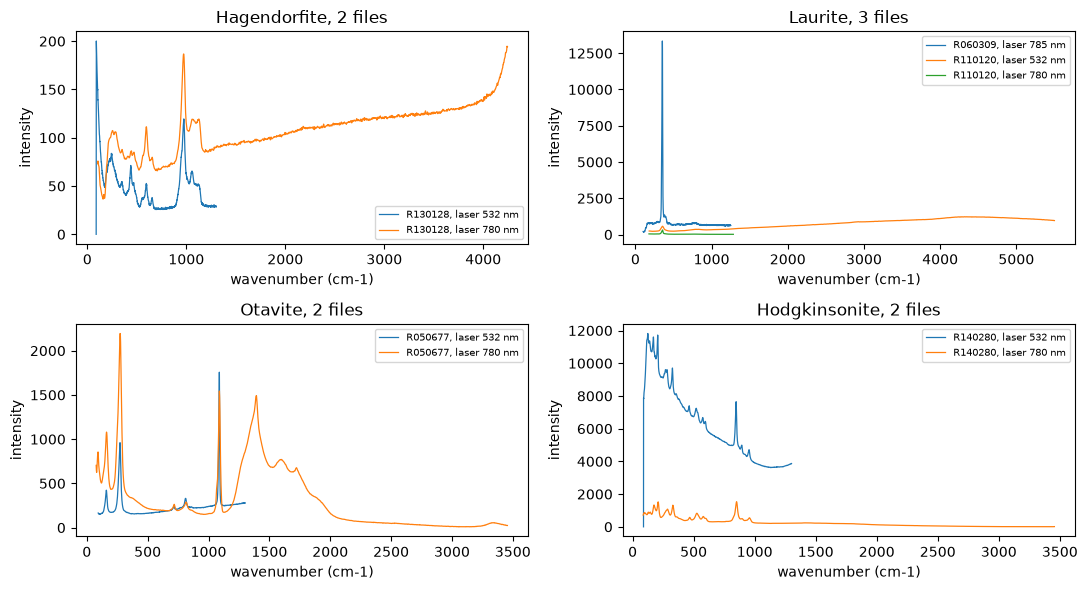

In [9]:
LARGEST = ["Hagendorfite", "Laurite", "Otavite", "Hodgkinsonite"]

fig, axes = plt.subplots(2, 2, figsize=(11, 6))
for panel, mineral in zip(axes.ravel(), LARGEST):
    group = files[files.mineral == mineral]
    for row in group.itertuples(index=False):
        values = read_pairs(Path(row.path))
        panel.plot(values[:, 0], values[:, 1], lw=0.9,
                   label=f"{row.rruff_id}, laser {row.wavelength} nm")
    panel.set_title(f"{mineral}, {len(group)} files")
    panel.set_xlabel("wavenumber (cm-1)")
    panel.set_ylabel("intensity")
    panel.legend(fontsize=7)
plt.tight_layout()
plt.show()

In [10]:
per_laser = (files.groupby("wavelength").size()
            .rename("files")
            .sort_values(ascending=False)
            .to_frame())
per_laser.index.name = "laser (nm), as written in the file name"

print(f"{int(per_laser['files'].sum()):,} files over {len(per_laser)} laser excitations")
print()
print(per_laser.to_string())

9,041 files over 11 laser excitations

                                         files
laser (nm), as written in the file name       
514                                       4182
532                                       2612
780                                       1584
785                                        642
514-5                                        9
633                                          4
                                             4
458                                          1
53                                           1
532SP9                                       1
632-8                                        1


## 10. The same coverage difference, over the files at 514 nm

The files here are the kept set restricted to the laser excitation written as 514, so the files
whose field reads `514-5` are not among them, and RAW and confirmed as before. The cells below
report, for that set, the coverage difference per mineral, then how many minerals and files it holds
with the mean, smallest, largest and median number of files per mineral, and then which of those
minerals the two archives each contribute.


In [11]:
at_514 = files[files.wavelength == "514"]

coverage_514 = coverage_by_mineral(at_514)

print(f"{len(at_514):,} files at 514 nm, across {at_514.mineral.nunique():,} minerals")
print()
print(coverage_514.round({"mean": 2, "min": 2, "max": 2, "median": 2}).to_string(index=False))

4,182 files at 514 nm, across 300 minerals

                  mineral  files  pairs   mean    min    max  median
               Actinolite     61   1830  66.88   0.00 198.64   61.16
                  Adamite     20    190  49.87   1.17 141.39   42.75
                 Aegirine     26    325  40.87   0.00 117.52   38.61
              Aenigmatite     15    105  19.49   2.26  57.63   14.83
               Akermanite     12     66  32.26   0.00  60.36   40.78
                   Albite     70   2415 170.06   0.00 438.84   93.97
                Almandine     25    300  76.33   0.00 173.19   70.12
                 Alum-(K)      1      0    NaN    NaN    NaN     NaN
              Amblygonite     19    171  81.80   0.00 284.62   17.51
                  Amesite      6     15  20.15   0.00  35.77   30.83
                 Analcime     17    136  54.03   0.00 136.01   12.19
                  Anatase      6     15   0.00   0.00   0.00    0.00
               Andalusite     56   1540  28.74   0.00 149.0

In [12]:
per_mineral = at_514.groupby("mineral").size()

summary = pd.DataFrame({
    "minerals": [int(per_mineral.size)],
    "files": [int(len(at_514))],
    "mean": [float(per_mineral.mean())],
    "min": [int(per_mineral.min())],
    "max": [int(per_mineral.max())],
    "median": [float(per_mineral.median())],
})

print(summary.round({"mean": 2, "median": 2}).to_string(index=False))

 minerals  files  mean  min  max  median
      300   4182 13.94    1  104    10.0


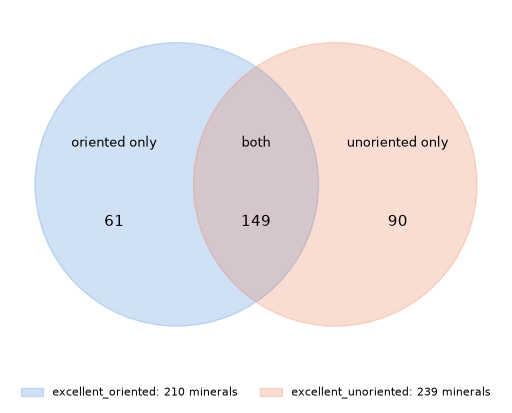

minerals in oriented only: 61, in both archives: 149, in unoriented only: 90


In [13]:
oriented = set(at_514.mineral[at_514.archive == "excellent_oriented"])
unoriented = set(at_514.mineral[at_514.archive == "excellent_unoriented"])
in_both = oriented & unoriented

fig, panel = plt.subplots(figsize=(6.2, 4.2))
for centre, colour, name, count in ((0.40, "#2a78d6", "excellent_oriented", len(oriented)),
                                    (0.78, "#eb6834", "excellent_unoriented", len(unoriented))):
    panel.add_patch(plt.Circle((centre, 0.0), 0.34, color=colour, alpha=0.22,
                               label=f"{name}: {count} minerals"))

panel.text(0.25, 0.10, "oriented only", ha="center", va="center", fontsize=9)
panel.text(0.25, -0.09, f"{len(oriented - in_both)}", ha="center", va="center", fontsize=11)
panel.text(0.59, 0.10, "both", ha="center", va="center", fontsize=9)
panel.text(0.59, -0.09, f"{len(in_both)}", ha="center", va="center", fontsize=11)
panel.text(0.93, 0.10, "unoriented only", ha="center", va="center", fontsize=9)
panel.text(0.93, -0.09, f"{len(unoriented - in_both)}", ha="center", va="center", fontsize=11)

panel.set_xlim(0.0, 1.18)
panel.set_ylim(-0.42, 0.42)
panel.set_aspect("equal")
panel.axis("off")
panel.legend(loc="lower center", fontsize=8, frameon=False, ncol=2, bbox_to_anchor=(0.5, -0.14))
plt.tight_layout()
plt.show()

print(f"minerals in oriented only: {len(oriented - in_both)}, "
      f"in both archives: {len(in_both)}, "
      f"in unoriented only: {len(unoriented - in_both)}")

## 11. What this covers

| Section | Reports |
| --- | --- |
| 3 | the files the set keeps, and the RAW and confirmed filter they pass, archive by archive |
| 4 | the wavenumber range each kept file spans, and the mineral it belongs to |
| 5 | one row per mineral: its file count, the ranges its files span, and whether they differ |
| 6 | one row per file of every mineral whose files span more than one range |
| 7 | for each mineral, the mean, smallest, largest and median difference in range coverage over every pair of its files |
| 8 | the same table ordered by the mean, largest first |
| 9 | every spectrum of the four minerals at the head of that table, one line per file, its laser excitation named in the legend, and the number of files per laser excitation across the set |
| 10 | the same coverage difference over the files whose laser excitation reads 514, their mineral and file counts, and a diagram of which archive contributes which mineral |

Nothing here trims a file or places it on a shared axis: the ranges reported are the ranges the
exports were written on.


## 12. Reproducing

```
cd /home/raj/projects/SH_Project
MPLBACKEND=Agg .venv/bin/jupyter execute --inplace --kernel_name sh_project notebooks/raw_excellent.ipynb
```

The archives are read from `~/Desktop/raman_data`, or from `RRUFF_DATA` when that is set.
